In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0012706.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0010192.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0010017.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0013000.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0013166.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0003308.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0012332.jpg
/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input/ISIC_0014291.jpg
/kaggle/

In [1]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
# Training Images
image_dir = "/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1-2_Training_Input"

# Ground Truth Masks
mask_dir = "/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation/ISIC2018_Task1_Training_GroundTruth"

In [3]:
images = sorted([f for f in os.listdir(image_dir) if f.endswith(".jpg")])
masks = sorted([f for f in os.listdir(mask_dir) if f.endswith(".png")])

print("Number of Training Images :", len(images))
print("Number of Ground Truth Masks :", len(masks))

Number of Training Images : 2594
Number of Ground Truth Masks : 2594


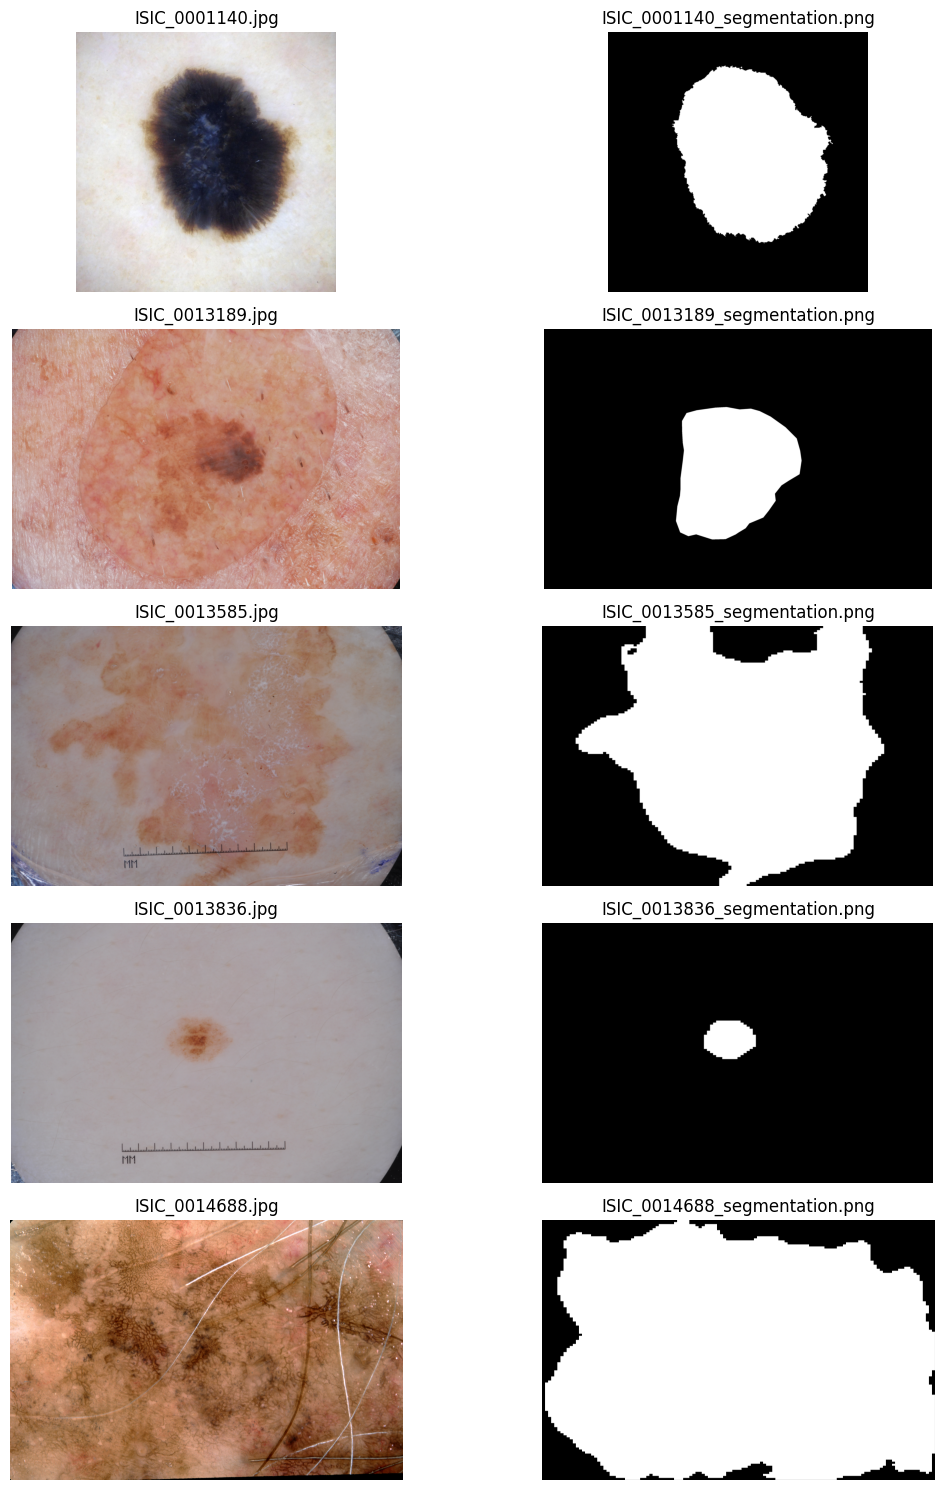

In [4]:
random_samples = random.sample(images, 5)

plt.figure(figsize=(12, 15))

for i, img_name in enumerate(random_samples):

    # Image path
    img_path = os.path.join(image_dir, img_name)

    # Mask name
    mask_name = img_name.replace(".jpg", "_segmentation.png")
    mask_path = os.path.join(mask_dir, mask_name)

    # Read image and mask
    image = Image.open(img_path)
    mask = Image.open(mask_path)

    # Display image
    plt.subplot(5, 2, 2*i+1)
    plt.imshow(image)
    plt.title(img_name)
    plt.axis("off")

    # Display mask
    plt.subplot(5, 2, 2*i+2)
    plt.imshow(mask, cmap="gray")
    plt.title(mask_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
print("="*50)
print("IMAGE & MASK INFORMATION")
print("="*50)

for i in range(5):

    img_name = images[i]

    mask_name = img_name.replace(".jpg", "_segmentation.png")

    image = Image.open(os.path.join(image_dir, img_name))
    mask = Image.open(os.path.join(mask_dir, mask_name))

    print(f"\nImage : {img_name}")
    print(f"Image Size : {image.size}")
    print(f"Mask Size  : {mask.size}")
    print(f"Image Mode : {image.mode}")
    print(f"Mask Mode  : {mask.mode}")

IMAGE & MASK INFORMATION

Image : ISIC_0000000.jpg
Image Size : (1022, 767)
Mask Size  : (1022, 767)
Image Mode : RGB
Mask Mode  : L

Image : ISIC_0000001.jpg
Image Size : (1022, 767)
Mask Size  : (1022, 767)
Image Mode : RGB
Mask Mode  : L

Image : ISIC_0000003.jpg
Image Size : (1022, 767)
Mask Size  : (1022, 767)
Image Mode : RGB
Mask Mode  : L

Image : ISIC_0000004.jpg
Image Size : (1022, 767)
Mask Size  : (1022, 767)
Image Mode : RGB
Mask Mode  : L

Image : ISIC_0000006.jpg
Image Size : (1022, 767)
Mask Size  : (1022, 767)
Image Mode : RGB
Mask Mode  : L


In [6]:
missing_masks = []

for img_name in images:

    mask_name = img_name.replace(".jpg", "_segmentation.png")

    if not os.path.exists(os.path.join(mask_dir, mask_name)):
        missing_masks.append(img_name)


print("PAIR VERIFICATION")


if len(missing_masks) == 0:
    print("✅ Every image has a corresponding mask.")
else:
    print("Missing Masks :", len(missing_masks))
    print(missing_masks[:10])

PAIR VERIFICATION
✅ Every image has a corresponding mask.


In [7]:
corrupted_images = []

for img_name in images:

    try:
        Image.open(os.path.join(image_dir, img_name)).verify()
    except:
        corrupted_images.append(img_name)


print("CORRUPTED IMAGE CHECK")


if len(corrupted_images)==0:
    print("✅ No corrupted images found.")
else:
    print("Corrupted Images :", corrupted_images)

CORRUPTED IMAGE CHECK
✅ No corrupted images found.


In [8]:
corrupted_masks = []

for mask_name in masks:

    try:
        Image.open(os.path.join(mask_dir, mask_name)).verify()
    except:
        corrupted_masks.append(mask_name)


print("CORRUPTED MASK CHECK")


if len(corrupted_masks)==0:
    print("✅ No corrupted masks found.")
else:
    print("Corrupted Masks :", corrupted_masks)

CORRUPTED MASK CHECK
✅ No corrupted masks found.


PREPROCESSING COMPLETED
Images Shape : (2594, 256, 256, 3)
Masks Shape  : (2594, 256, 256)
Image Range  : 0.0 - 1.0
Mask Values  : [0. 1.]


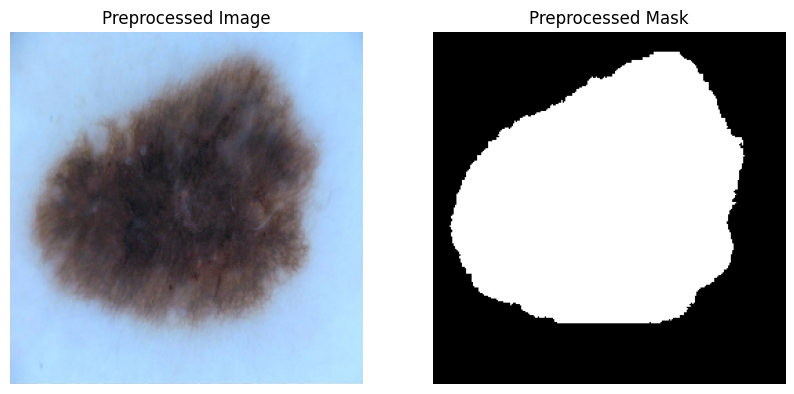

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Image size
IMG_SIZE = 256

# Lists to store processed data
processed_images = []
processed_masks = []

# Process all images and masks
for img_name in images:

    # Image path
    img_path = os.path.join(image_dir, img_name)

    # Corresponding mask path
    mask_name = img_name.replace(".jpg", "_segmentation.png")
    mask_path = os.path.join(mask_dir, mask_name)

    # Read image
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image.astype(np.float32) / 255.0

    # Read mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
    mask = mask.astype(np.float32) / 255.0

    # Convert mask to binary
    mask = (mask > 0.5).astype(np.float32)

    # Store
    processed_images.append(image)
    processed_masks.append(mask)

# Convert to NumPy arrays
processed_images = np.array(processed_images)
processed_masks = np.array(processed_masks)


print("PREPROCESSING COMPLETED")

print("Images Shape :", processed_images.shape)
print("Masks Shape  :", processed_masks.shape)
print("Image Range  :", processed_images.min(), "-", processed_images.max())
print("Mask Values  :", np.unique(processed_masks))

# Display one sample
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(processed_images[0])
plt.title("Preprocessed Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(processed_masks[0], cmap="gray")
plt.title("Preprocessed Mask")
plt.axis("off")

plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
import torch


# Train-Validation Split

X_train, X_val, y_train, y_val = train_test_split(
    processed_images,
    processed_masks,
    test_size=0.2,
    random_state=42
)

print("Training Images :", len(X_train))
print("Validation Images :", len(X_val))


# -------------------------------
# Custom Dataset
# -------------------------------
class SkinLesionDataset(Dataset):

    def __init__(self, images, masks):
        self.images = images
        self.masks = masks

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx],
            dtype=torch.float32
        ).permute(2,0,1)

        mask = torch.tensor(
            self.masks[idx],
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask


# -------------------------------
# Create Dataset
# -------------------------------
train_dataset = SkinLesionDataset(X_train, y_train)
val_dataset = SkinLesionDataset(X_val, y_val)


# -------------------------------
# Create DataLoader
# -------------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)


print("\nDataLoader Created Successfully!")

print("Training Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))

Training Images : 2075
Validation Images : 519

DataLoader Created Successfully!
Training Batches : 260
Validation Batches : 65


**Now , We Built Unet Archeitecture
Built Unet model***

In [11]:
import torch
import torch.nn as nn

# -----------------------------
# Double Convolution Block
# -----------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# -----------------------------
# U-Net Model
# -----------------------------
class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.down1 = DoubleConv(3,64)
        self.pool1 = nn.MaxPool2d(2)

        self.down2 = DoubleConv(64,128)
        self.pool2 = nn.MaxPool2d(2)

        self.down3 = DoubleConv(128,256)
        self.pool3 = nn.MaxPool2d(2)

        self.down4 = DoubleConv(256,512)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512,1024)

        self.up4 = nn.ConvTranspose2d(1024,512,2,2)
        self.conv4 = DoubleConv(1024,512)

        self.up3 = nn.ConvTranspose2d(512,256,2,2)
        self.conv3 = DoubleConv(512,256)

        self.up2 = nn.ConvTranspose2d(256,128,2,2)
        self.conv2 = DoubleConv(256,128)

        self.up1 = nn.ConvTranspose2d(128,64,2,2)
        self.conv1 = DoubleConv(128,64)

        self.final = nn.Conv2d(64,1,kernel_size=1)

    def forward(self,x):

        c1 = self.down1(x)
        p1 = self.pool1(c1)

        c2 = self.down2(p1)
        p2 = self.pool2(c2)

        c3 = self.down3(p2)
        p3 = self.pool3(c3)

        c4 = self.down4(p3)
        p4 = self.pool4(c4)

        bn = self.bottleneck(p4)

        u4 = self.up4(bn)
        u4 = torch.cat([u4,c4],dim=1)
        u4 = self.conv4(u4)

        u3 = self.up3(u4)
        u3 = torch.cat([u3,c3],dim=1)
        u3 = self.conv3(u3)

        u2 = self.up2(u3)
        u2 = torch.cat([u2,c2],dim=1)
        u2 = self.conv2(u2)

        u1 = self.up1(u2)
        u1 = torch.cat([u1,c1],dim=1)
        u1 = self.conv1(u1)

        return torch.sigmoid(self.final(u1))



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

print(model)
print("\nModel Created Successfully!")
print("Running on :", device)

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (

In [12]:
import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch Version: 2.10.0+cu128
GPU Available: True
GPU Name: Tesla T4


**Now , We Train Unet model****

**Define Loss Function & Optimizer****

In [18]:

import torch
import torch.nn as nn
import torch.optim as optim

# Binary Cross Entropy Loss
criterion = nn.BCELoss()

# Adam Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Number of Epochs
num_epochs = 30

print("Loss Function :", criterion)
print("Optimizer :", optimizer)
print("Epochs :", num_epochs)

Loss Function : BCELoss()
Optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Epochs : 30


In [14]:
best_val_loss = float("inf")

for epoch in range(num_epochs):

    # -----------------------
    # Training
    # -----------------------
    model.train()
    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -----------------------
    # Validation
    # -----------------------
    model.eval()

    val_loss = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = criterion(outputs, masks)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} "
          f"Validation Loss: {val_loss:.4f}")

    # -----------------------
    # Save Best Model
    # -----------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(model.state_dict(), "unet_model.pth")

        print("✅ Best Model Saved!")

Epoch [1/30] Train Loss: 1.0340 Validation Loss: 0.8380
✅ Best Model Saved!
Epoch [2/30] Train Loss: 0.8100 Validation Loss: 0.7359
✅ Best Model Saved!
Epoch [3/30] Train Loss: 0.6472 Validation Loss: 0.5458
✅ Best Model Saved!
Epoch [4/30] Train Loss: 0.5451 Validation Loss: 0.5152
✅ Best Model Saved!
Epoch [5/30] Train Loss: 0.4654 Validation Loss: 0.4571
✅ Best Model Saved!
Epoch [6/30] Train Loss: 0.4341 Validation Loss: 0.4115
✅ Best Model Saved!
Epoch [7/30] Train Loss: 0.3830 Validation Loss: 0.4061
✅ Best Model Saved!
Epoch [8/30] Train Loss: 0.3619 Validation Loss: 0.3649
✅ Best Model Saved!
Epoch [9/30] Train Loss: 0.3434 Validation Loss: 0.3899
Epoch [10/30] Train Loss: 0.3368 Validation Loss: 0.3621
✅ Best Model Saved!
Epoch [11/30] Train Loss: 0.3338 Validation Loss: 0.3556
✅ Best Model Saved!
Epoch [12/30] Train Loss: 0.3294 Validation Loss: 0.3327
✅ Best Model Saved!
Epoch [13/30] Train Loss: 0.3199 Validation Loss: 0.3390
Epoch [14/30] Train Loss: 0.3176 Validation Loss

In [15]:
model.load_state_dict(torch.load("unet_model.pth"))
model.eval()

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (

✅ Best U-Net Model Loaded Successfully!


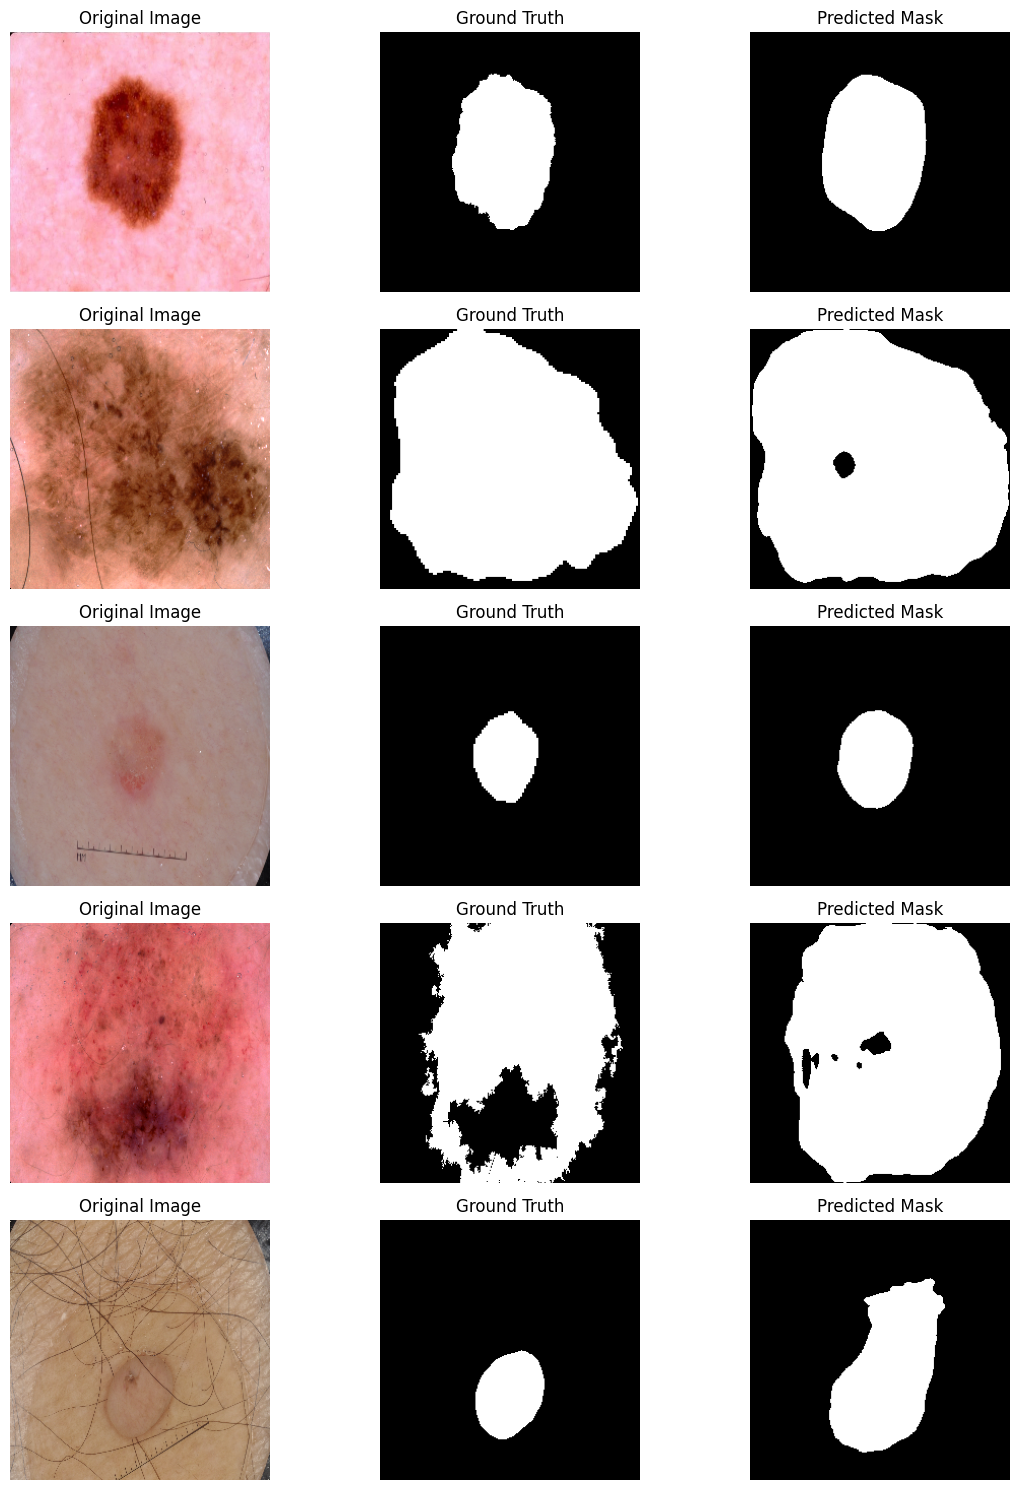

In [16]:
import matplotlib.pyplot as plt
import torch

# -----------------------------
# Load Best Model
# -----------------------------
model.load_state_dict(torch.load("/kaggle/working/unet_model.pth"))
model.eval()

print("✅ Best U-Net Model Loaded Successfully!")

# -----------------------------
# Predict on 5 Validation Images
# -----------------------------
num_samples = 5

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 15))

with torch.no_grad():

    for i in range(num_samples):

        # Get one sample
        image, mask = val_dataset[i]

        # Add batch dimension
        input_image = image.unsqueeze(0).to(device)

        # Prediction
        pred_mask = model(input_image)

        # Convert tensors to numpy
        image_np = image.permute(1, 2, 0).cpu().numpy()
        true_mask = mask.squeeze().cpu().numpy()
        pred_mask = pred_mask.squeeze().cpu().numpy()

        # Threshold prediction
        pred_mask = (pred_mask > 0.5).astype("float32")

        # Display Original Image
        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Original Image")
        axes[i, 0].axis("off")

        # Display Ground Truth
        axes[i, 1].imshow(true_mask, cmap="gray")
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        # Display Prediction
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title("Predicted Mask")
        axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import torch


# Dice Score Function

def dice_score(pred, target, smooth=1e-6):
    pred = pred.reshape(-1)
    target = target.reshape(-1)

    intersection = (pred * target).sum()

    return (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)


# -----------------------------
# IoU Function
# -----------------------------
def iou_score(pred, target, smooth=1e-6):
    pred = pred.reshape(-1)
    target = target.reshape(-1)

    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection

    return (intersection + smooth) / (union + smooth)



# Evaluate on Validation Dataset

model.eval()

dice_scores = []
iou_scores = []

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        outputs = (outputs > 0.5).float()

        for i in range(outputs.size(0)):

            pred = outputs[i].cpu().numpy()
            true = masks[i].cpu().numpy()

            dice_scores.append(dice_score(pred, true))
            iou_scores.append(iou_score(pred, true))

print("="*50)
print("MODEL EVALUATION")
print("="*50)
print(f"Average Dice Score : {np.mean(dice_scores):.4f}")
print(f"Average IoU Score  : {np.mean(iou_scores):.4f}")

MODEL EVALUATION
Average Dice Score : 0.8537
Average IoU Score  : 0.7705
